# Thermal-IR Dataset 1 and Dataset 2 Exploratory Data Analysis

This notebook documents the thermal source properties used in the project. It analyzes the Dataset 2 drone-versus-bird subset, the Dataset 1 Anti-UAV training partition, and a descriptive comparison of their normalized bounding-box properties. It reads validated manifests and source annotations without changing raw data.

Run the source-manifest validation stage in `02_thermal_ir_pipeline.ipynb` before running this notebook. Dataset 1 supplied test folders remain inference-only and are not included in these summaries or the reported Dataset 2-only evaluation.

In [1]:
from __future__ import annotations

import json

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from mcos_decoder import load_groundtruth

WORKING_DIRECTORY = Path.cwd().resolve()
if (WORKING_DIRECTORY / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY
elif (WORKING_DIRECTORY.parent / '.git').is_dir():
    REPO_ROOT = WORKING_DIRECTORY.parent
else:
    raise RuntimeError('Run this notebook from the repository root or notebooks directory.')

THERMAL_ROOT = REPO_ROOT / 'data' / 'thermal-ir'
MANIFEST_PATH = THERMAL_ROOT / 'manifests' / 'dataset2_videos.csv'
ISSUES_PATH = THERMAL_ROOT / 'manifests' / 'annotation_issues.csv'
BOX_SUMMARY_PATH = THERMAL_ROOT / 'interim' / 'eda' / 'dataset2_box_summary.csv'
FIGURE_DIR = REPO_ROOT / 'results' / 'thermal-ir' / 'eda' / 'dataset2'

for required_path in (MANIFEST_PATH, ISSUES_PATH):
    if not required_path.is_file():
        raise FileNotFoundError(f'Missing {required_path}. Run 02_thermal_ir_pipeline.ipynb first.')

BOX_SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams['figure.dpi'] = 120


## 1. Dataset 2 recording inventory, duration, and annotation issues

Drone and bird recordings form the current analysis subset. Airplane and helicopter recordings remain in the source manifest for provenance, but are excluded from these drone-versus-bird summaries.

,recordings,video_frames,annotation_entries,visible_annotations,duration_seconds_median,recordings_with_length_mismatch
source_class,,,,,,
BIRD,79,24854,24544,21967,10.47,79
DRONE,157,49043,49187,47622,10.40,4


,count
issue_type,
video_annotation_length_mismatch,85


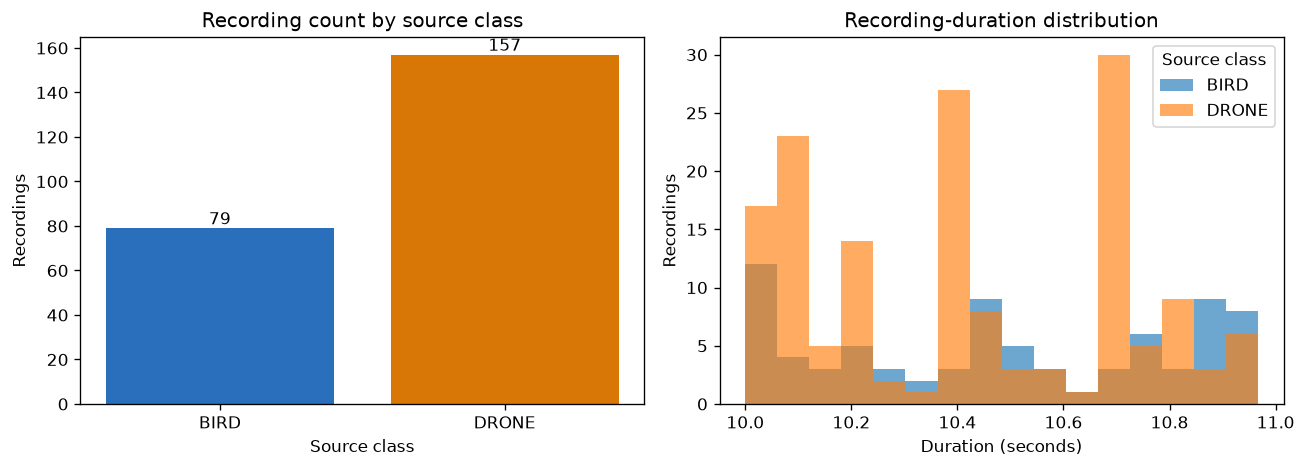

In [2]:
videos = pd.read_csv(MANIFEST_PATH)
issues = pd.read_csv(ISSUES_PATH)
eligible = videos.loc[videos['export_policy'].isin(['positive_drone', 'negative_bird'])].copy()
eligible['duration_seconds'] = eligible['video_frame_count'] / eligible['fps']
eligible['frame_annotation_difference'] = eligible['video_frame_count'] - eligible['annotation_entries']
eligible['length_mismatch'] = eligible['frame_annotation_difference'].ne(0)

inventory = (
    eligible.groupby('source_class')
    .agg(
        recordings=('source_sequence', 'count'),
        video_frames=('video_frame_count', 'sum'),
        annotation_entries=('annotation_entries', 'sum'),
        visible_annotations=('visible_entries', 'sum'),
        duration_seconds_median=('duration_seconds', 'median'),
        recordings_with_length_mismatch=('length_mismatch', 'sum'),
    )
    .round(2)
)
display(inventory)

issue_counts = (
    issues.loc[issues['source_dataset'].eq('drone_detection_dataset2')]
    .groupby('issue_type').size().rename('count').to_frame()
)
display(issue_counts)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = eligible['source_class'].value_counts().sort_index()
axes[0].bar(counts.index, counts.values, color=['#2a6fbb', '#d97706'])
axes[0].set(title='Recording count by source class', xlabel='Source class', ylabel='Recordings')
for index, value in enumerate(counts.values):
    axes[0].text(index, value, str(value), ha='center', va='bottom')
for source_class, group in eligible.groupby('source_class'):
    axes[1].hist(group['duration_seconds'], bins=16, alpha=0.65, label=source_class)
axes[1].set(title='Recording-duration distribution', xlabel='Duration (seconds)', ylabel='Recordings')
axes[1].legend(title='Source class')
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'recording_counts_and_durations.png', bbox_inches='tight')
plt.show()


## 2. Dataset 2 bounding-box area, aspect ratio, and target location

The source annotations are decoded for both drone and bird recordings. Bird boxes are descriptive EDA information only; the one-class derived dataset continues to use empty labels for bird frames. Invalid or out-of-frame boxes are omitted from geometry summaries and counted. These Dataset 2 figures do not include Dataset 1.

In [3]:
def valid_xywh(box, image_width, image_height):
    if box is None or len(box) != 4:
        return False
    x, y, width, height = (float(value) for value in box)
    return (
        np.isfinite([x, y, width, height]).all()
        and width > 0 and height > 0
        and x >= 0 and y >= 0
        and x + width <= image_width and y + height <= image_height
    )

box_rows, invalid_box_count = [], 0
for record in eligible.itertuples(index=False):
    annotation_path = REPO_ROOT / record.annotation_path
    for frame_number, box in enumerate(load_groundtruth(annotation_path), start=1):
        if box is None:
            continue
        if not valid_xywh(box, record.image_width, record.image_height):
            invalid_box_count += 1
            continue
        x, y, width, height = (float(value) for value in box)
        area = width * height
        box_rows.append({
            'source_sequence': record.source_sequence,
            'source_class': record.source_class,
            'frame_number': frame_number,
            'area_pixels': area,
            'area_fraction': area / (record.image_width * record.image_height),
            'aspect_ratio': width / height,
            'center_x_fraction': (x + width / 2) / record.image_width,
            'center_y_fraction': (y + height / 2) / record.image_height,
        })

boxes = pd.DataFrame(box_rows)
if boxes.empty:
    raise ValueError('No valid boxes were decoded; inspect the source manifest and mcos-decoder installation.')
boxes.to_csv(BOX_SUMMARY_PATH, index=False)
print(f'Wrote {len(boxes):,} valid boxes to {BOX_SUMMARY_PATH.relative_to(REPO_ROOT)}')
print(f'Excluded {invalid_box_count:,} invalid source boxes from geometry summaries.')

geometry_summary = (
    boxes.groupby('source_class')
    .agg(
        boxes=('frame_number', 'count'),
        median_area_pixels=('area_pixels', 'median'),
        median_area_fraction=('area_fraction', 'median'),
        median_aspect_ratio=('aspect_ratio', 'median'),
        median_center_x=('center_x_fraction', 'median'),
        median_center_y=('center_y_fraction', 'median'),
    )
    .round(4)
)
display(geometry_summary)


Wrote 69,589 valid boxes to data\thermal-ir\interim\eda\dataset2_box_summary.csv
Excluded 0 invalid source boxes from geometry summaries.


,boxes,median_area_pixels,median_area_fraction,median_aspect_ratio,median_center_x,median_center_y
source_class,,,,,,
BIRD,21967,177.6667,0.0022,1.1224,0.4781,0.4422
DRONE,47622,218.8867,0.0027,1.4990,0.5747,0.3895


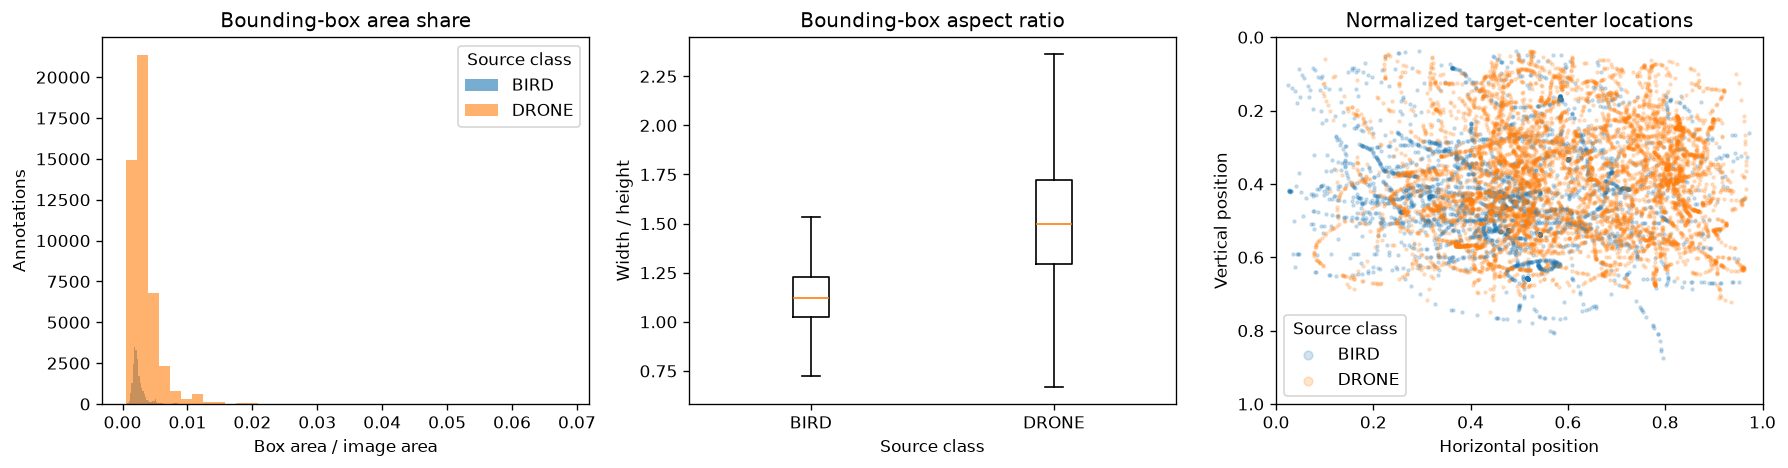

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for source_class, group in boxes.groupby('source_class'):
    axes[0].hist(group['area_fraction'], bins=40, alpha=0.6, label=source_class)
axes[0].set(title='Bounding-box area share', xlabel='Box area / image area', ylabel='Annotations')
axes[0].legend(title='Source class')

aspect_groups = [group['aspect_ratio'].values for _, group in boxes.groupby('source_class')]
aspect_labels = [name for name, _ in boxes.groupby('source_class')]
axes[1].boxplot(aspect_groups, tick_labels=aspect_labels, showfliers=False)
axes[1].set(title='Bounding-box aspect ratio', xlabel='Source class', ylabel='Width / height')

sample = boxes.sample(n=min(10000, len(boxes)), random_state=42)
for source_class, group in sample.groupby('source_class'):
    axes[2].scatter(group['center_x_fraction'], group['center_y_fraction'], s=3, alpha=0.2, label=source_class)
axes[2].set(title='Normalized target-center locations', xlabel='Horizontal position', ylabel='Vertical position', xlim=(0, 1), ylim=(1, 0))
axes[2].legend(title='Source class', markerscale=3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / 'box_geometry_and_target_location.png', bbox_inches='tight')
plt.show()


In [5]:
dataset2_summary = {
    'scope': 'Dataset 2 drone-versus-bird subset only; airplane and helicopter recordings are excluded',
    'recording_counts': {key: int(value) for key, value in eligible['source_class'].value_counts().sort_index().items()},
    'video_frame_counts': {key: int(value) for key, value in eligible.groupby('source_class')['video_frame_count'].sum().sort_index().items()},
    'annotation_entry_counts': {key: int(value) for key, value in eligible.groupby('source_class')['annotation_entries'].sum().sort_index().items()},
    'video_annotation_length_mismatches': int((issues['source_dataset'].eq('drone_detection_dataset2') & issues['issue_type'].eq('video_annotation_length_mismatch')).sum()),
    'valid_box_count': int(len(boxes)),
    'geometry_by_source_class': {
        source_class: {
            'median_area_fraction': float(group['area_fraction'].median()),
            'median_aspect_ratio': float(group['aspect_ratio'].median()),
            'median_center_x': float(group['center_x_fraction'].median()),
            'median_center_y': float(group['center_y_fraction'].median()),
        }
        for source_class, group in boxes.groupby('source_class')
    },
}
(FIGURE_DIR / 'eda_summary.json').write_text(json.dumps(dataset2_summary, indent=2), encoding='utf-8')
display(pd.Series(dataset2_summary))


scope                                 Dataset 2 drone-versus-bird subset only; airpl...
recording_counts                                             {'BIRD': 79, 'DRONE': 157}
video_frame_counts                                      {'BIRD': 24854, 'DRONE': 49043}
annotation_entry_counts                                 {'BIRD': 24544, 'DRONE': 49187}
video_annotation_length_mismatches                                                   85
valid_box_count                                                                   69589
geometry_by_source_class              {'BIRD': {'median_area_fraction': 0.0021687825...
dtype: object

## 3. Dataset 1 source characteristics and geometry

Dataset 1 is analyzed separately because it contains drone annotations only and has different source conditions from Dataset 2. This cell reads the Dataset 1 train manifest and annotations without modifying raw files. Its test folders remain outside this EDA and outside reported evaluation.

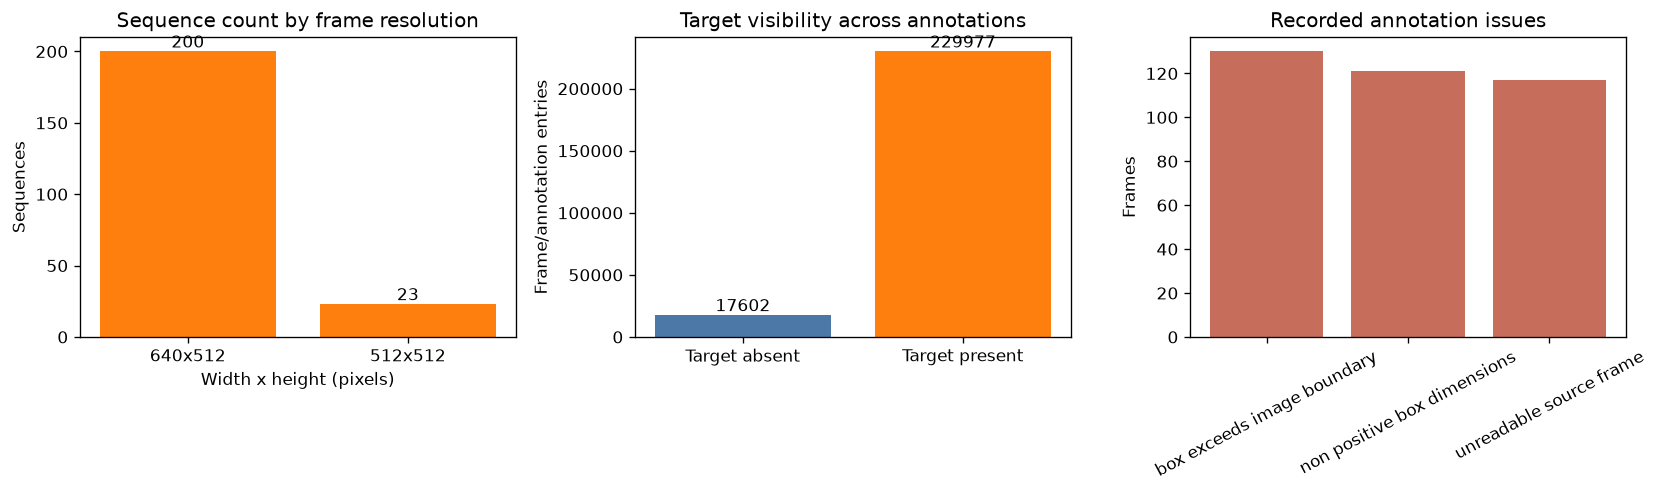

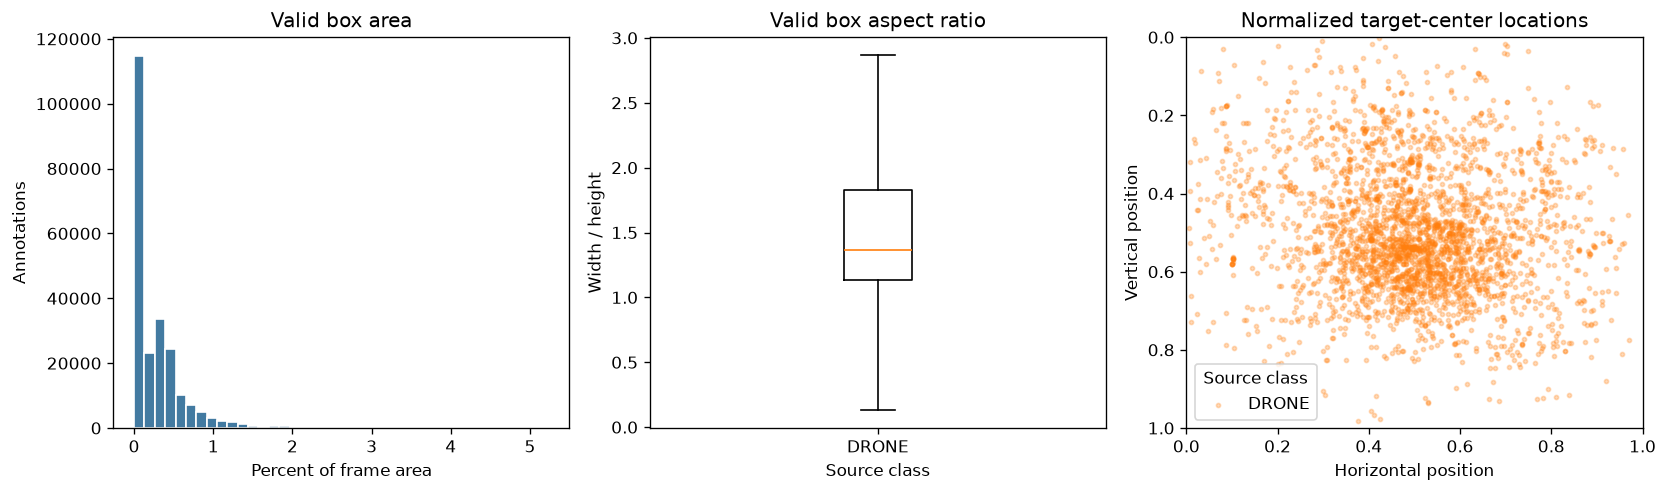

scope              Dataset 1 Anti-UAV train partition only; test ...
sequence_count                                                   223
frame_count                                                   247579
visible_entries                                               229977
absent_entries                                                 17602
valid_box_count                                               229726
issue_counts       {'box_exceeds_image_boundary': 130, 'non_posit...
dtype: object

In [6]:
import json

DATASET1_MANIFEST_PATH = THERMAL_ROOT / 'manifests' / 'dataset1_sequences.csv'
DATASET1_RAW_ROOT = THERMAL_ROOT / 'raw' / 'anti_uav_dataset1' / 'train'
DATASET1_BOX_SUMMARY_PATH = THERMAL_ROOT / 'interim' / 'eda' / 'dataset1_box_summary.csv'
DATASET1_FIGURE_DIR = REPO_ROOT / 'results' / 'thermal-ir' / 'eda' / 'dataset1'
for required_path in (DATASET1_MANIFEST_PATH, DATASET1_RAW_ROOT):
    if not required_path.exists():
        raise FileNotFoundError(f'Missing {required_path}. Run the Dataset 1 source-manifest stage first.')
DATASET1_FIGURE_DIR.mkdir(parents=True, exist_ok=True)

dataset1_manifest = pd.read_csv(DATASET1_MANIFEST_PATH)
dataset1_issues = issues.loc[issues['source_dataset'].eq('anti_uav_dataset1')].copy()
dataset1_issue_counts = dataset1_issues['issue_type'].value_counts().sort_index()
dataset1_rows = []
for record in dataset1_manifest.itertuples(index=False):
    labels = json.loads((REPO_ROOT / record.annotation_path).read_text(encoding='utf-8'))
    for frame_number, (exists, box) in enumerate(zip(labels['exist'], labels['gt_rect']), start=1):
        if exists != 1 or not valid_xywh(box, record.image_width, record.image_height):
            continue
        x, y, width, height = (float(value) for value in box)
        dataset1_rows.append({
            'source_sequence': record.source_sequence, 'frame_number': frame_number,
            'box_area_fraction': width * height / (record.image_width * record.image_height),
            'aspect_ratio': width / height,
            'center_x_normalized': (x + width / 2) / record.image_width,
            'center_y_normalized': (y + height / 2) / record.image_height,
        })
dataset1_boxes = pd.DataFrame(dataset1_rows)
if dataset1_boxes.empty:
    raise ValueError('No valid Dataset 1 boxes were found.')
DATASET1_BOX_SUMMARY_PATH.parent.mkdir(parents=True, exist_ok=True)
dataset1_boxes.to_csv(DATASET1_BOX_SUMMARY_PATH, index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
resolution_counts = dataset1_manifest.groupby(['image_width', 'image_height']).size().sort_values(ascending=False)
axes[0].bar([f'{width}x{height}' for width, height in resolution_counts.index], resolution_counts.values, color='#ff7f0e')
axes[0].bar_label(axes[0].containers[0])
axes[0].set(title='Sequence count by frame resolution', xlabel='Width x height (pixels)', ylabel='Sequences')
visibility_counts = pd.Series({'Target absent': dataset1_manifest['absent_entries'].sum(), 'Target present': dataset1_manifest['visible_entries'].sum()})
axes[1].bar(visibility_counts.index, visibility_counts.values, color=['#4c78a8', '#ff7f0e'])
axes[1].bar_label(axes[1].containers[0])
axes[1].set(title='Target visibility across annotations', ylabel='Frame/annotation entries')
axes[2].bar(dataset1_issue_counts.index.str.replace('_', ' '), dataset1_issue_counts.values, color='#c76d5b')
axes[2].tick_params(axis='x', rotation=28)
axes[2].set(title='Recorded annotation issues', ylabel='Frames')
fig.tight_layout()
fig.savefig(DATASET1_FIGURE_DIR / 'sequence_inventory_and_quality.png', bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].hist(dataset1_boxes['box_area_fraction'] * 100, bins=40, color='#427aa1', edgecolor='white')
axes[0].set(title='Valid box area', xlabel='Percent of frame area', ylabel='Annotations')
axes[1].boxplot([dataset1_boxes['aspect_ratio']], tick_labels=['DRONE'], showfliers=False)
axes[1].set(title='Valid box aspect ratio', xlabel='Source class', ylabel='Width / height')
dataset1_sample = dataset1_boxes.sample(n=min(len(dataset1_boxes), 3000), random_state=590)
axes[2].scatter(dataset1_sample['center_x_normalized'], dataset1_sample['center_y_normalized'], s=6, alpha=0.28, color='#ff7f0e', label='DRONE')
axes[2].set(title='Normalized target-center locations', xlabel='Horizontal position', ylabel='Vertical position', xlim=(0, 1), ylim=(1, 0))
axes[2].legend(title='Source class', loc='lower left')
fig.tight_layout()
fig.savefig(DATASET1_FIGURE_DIR / 'box_geometry_and_target_location.png', bbox_inches='tight')
plt.show()

dataset1_summary = {
    'scope': 'Dataset 1 Anti-UAV train partition only; test folders are not included',
    'sequence_count': int(len(dataset1_manifest)),
    'frame_count': int(dataset1_manifest['frame_count'].sum()),
    'visible_entries': int(dataset1_manifest['visible_entries'].sum()),
    'absent_entries': int(dataset1_manifest['absent_entries'].sum()),
    'valid_box_count': int(len(dataset1_boxes)),
    'issue_counts': {key: int(value) for key, value in dataset1_issue_counts.items()},
}
(DATASET1_FIGURE_DIR / 'eda_summary.json').write_text(json.dumps(dataset1_summary, indent=2), encoding='utf-8')
display(pd.Series(dataset1_summary))


## 4. Combined-source descriptive comparison

These figures compare Dataset 1 drones, Dataset 2 drones, and Dataset 2 birds using normalized annotation properties. They preserve source identity and do not create a merged training or evaluation dataset. Equal-size samples prevent Dataset 1's larger annotation count from visually dominating the location plot.

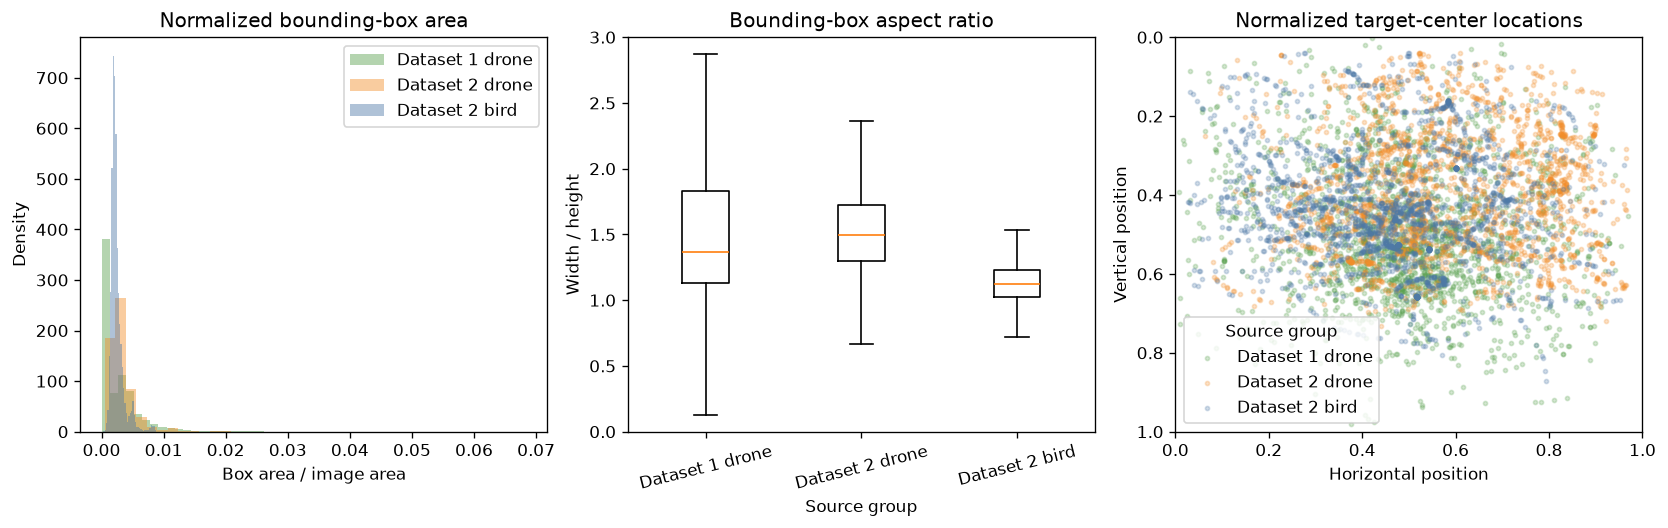

,valid_box_count,median_area_fraction,median_aspect_ratio,median_center_x,median_center_y
Dataset 1 drone,229726.0,0.001318,1.363636,0.496094,0.529297
Dataset 2 drone,47622.0,0.002672,1.499025,0.574676,0.389518
Dataset 2 bird,21967.0,0.002169,1.122363,0.478106,0.442195


In [7]:
COMBINED_FIGURE_DIR = REPO_ROOT / 'results' / 'thermal-ir' / 'eda' / 'combined'
COMBINED_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
dataset1_combined = dataset1_boxes.rename(columns={'box_area_fraction': 'area_fraction', 'center_x_normalized': 'center_x', 'center_y_normalized': 'center_y'}).assign(group='Dataset 1 drone')
dataset2_combined = boxes.rename(columns={'center_x_fraction': 'center_x', 'center_y_fraction': 'center_y'}).assign(group=lambda frame: frame['source_class'].map({'DRONE': 'Dataset 2 drone', 'BIRD': 'Dataset 2 bird'}))
combined_boxes = pd.concat([
    dataset1_combined[['group', 'area_fraction', 'aspect_ratio', 'center_x', 'center_y']],
    dataset2_combined[['group', 'area_fraction', 'aspect_ratio', 'center_x', 'center_y']],
], ignore_index=True)
group_order = ['Dataset 1 drone', 'Dataset 2 drone', 'Dataset 2 bird']
colors = {'Dataset 1 drone': '#59a14f', 'Dataset 2 drone': '#f28e2b', 'Dataset 2 bird': '#4e79a7'}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for group in group_order:
    values = combined_boxes.loc[combined_boxes['group'].eq(group), 'area_fraction']
    axes[0].hist(values, bins=40, density=True, alpha=0.45, color=colors[group], label=group)
axes[0].set(title='Normalized bounding-box area', xlabel='Box area / image area', ylabel='Density')
axes[0].legend()
aspect_groups = [combined_boxes.loc[combined_boxes['group'].eq(group), 'aspect_ratio'] for group in group_order]
axes[1].boxplot(aspect_groups, tick_labels=group_order, showfliers=False)
axes[1].set(title='Bounding-box aspect ratio', xlabel='Source group', ylabel='Width / height', ylim=(0, 3))
axes[1].tick_params(axis='x', rotation=14)
for group in group_order:
    group_rows = combined_boxes.loc[combined_boxes['group'].eq(group)]
    sample = group_rows.sample(n=min(2000, len(group_rows)), random_state=590)
    axes[2].scatter(sample['center_x'], sample['center_y'], s=6, alpha=0.25, color=colors[group], label=group)
axes[2].set(title='Normalized target-center locations', xlabel='Horizontal position', ylabel='Vertical position', xlim=(0, 1), ylim=(1, 0))
axes[2].legend(title='Source group', loc='lower left')
fig.tight_layout()
fig.savefig(COMBINED_FIGURE_DIR / 'combined_box_geometry_and_target_location.png', bbox_inches='tight')
plt.show()

combined_summary = {group: {
    'valid_box_count': int((combined_boxes['group'] == group).sum()),
    'median_area_fraction': float(combined_boxes.loc[combined_boxes['group'].eq(group), 'area_fraction'].median()),
    'median_aspect_ratio': float(combined_boxes.loc[combined_boxes['group'].eq(group), 'aspect_ratio'].median()),
    'median_center_x': float(combined_boxes.loc[combined_boxes['group'].eq(group), 'center_x'].median()),
    'median_center_y': float(combined_boxes.loc[combined_boxes['group'].eq(group), 'center_y'].median()),
} for group in group_order}
(COMBINED_FIGURE_DIR / 'eda_summary.json').write_text(json.dumps({'scope': 'Descriptive comparison of normalized annotations; not a merged training or evaluation dataset', 'groups': combined_summary}, indent=2), encoding='utf-8')
display(pd.DataFrame(combined_summary).T)
